In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns

In [9]:
import data                       

In [10]:
plt.style.use("../../nice.mplstyle")

In [11]:
fig_dir = "figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [12]:
ads = xr.open_dataset("runs/v3/metrics/sla.all_groups.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

In [13]:
sds = data.open_anemoi_statistics()
sds

<xarray.Dataset> Size: 3kB
Dimensions:   (variable: 36)
Coordinates:
  * variable  (variable) object 288B 'cos_julian_day' ... 'pooled'
Data variables:
    mean      (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    stdev     (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    minimum   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    maximum   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    sums      (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    squares   (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    count     (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
    has_nans  (variable) float64 288B dask.array<chunksize=(35,), meta=np.ndarray>
Attributes: (12/33)
    allow_nans:                    True
    area_check_max:                1.00117641972384
    area_check_min:                0.9992095208373832
    binned:                        True
    cell_selection:                gebco.land_fraction < 0.1
    constant_fields:               ['cos_latitude', 'cos_longitude', 'elevati...
    ...                            ...
    statistics_end_date:           2014-12-31T12:00:00
    statistics_start_date:         2000-01-01T12:00:00
    time_bin_closed:               left
    time_bin_label:                middle
    variables:                     ['cos_julian_day', 'cos_latitude', 'cos_lo...
    variables_metadata:            {'cos_julian_day': {'computed_forcing': Tr...

In [14]:
def histplot(metric, show_stdev=False):
    
    fig, axs = plt.subplots(1, 2, figsize=(12,5))
    
    ax = axs[0]
    for varname, label in zip(
        [metric, f"{metric}_pooled"],
        ["Raw Mean", "$N_{obs}$ Weighted"],
    ):
        sns.histplot(
            ads[varname],
            ax=ax,
            label=label,
        )

    if show_stdev:
        ax.axvline(x=sds["stdev"].sel(variable="pooled"), color="gray", label="Pooled Training Std. Dev.")
    ax.legend()
    
    ax = axs[1]
    for varname in [
        "n_obs",
    ]:
        ads[varname].plot(ax=ax, label=varname, color="C3")
        ax.set(title="")
        ax.legend()
        

    return fig, axs

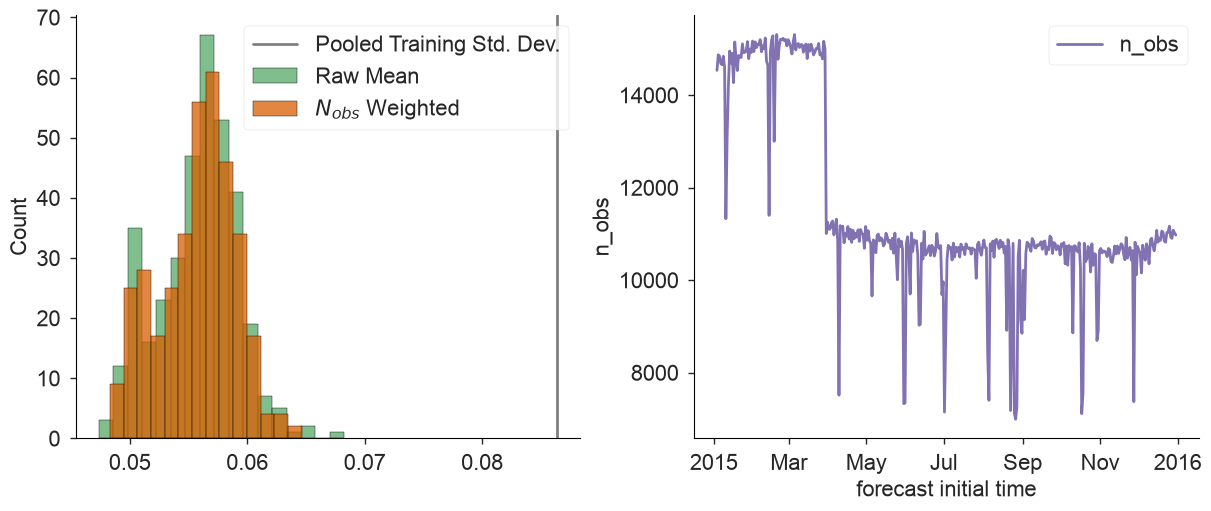

In [15]:
histplot("rmse", show_stdev=True);

(<Figure size 1200x500 with 2 Axes>,
 array([<Axes: ylabel='Count'>,
        <Axes: xlabel='forecast initial time', ylabel='n_obs'>],
       dtype=object))

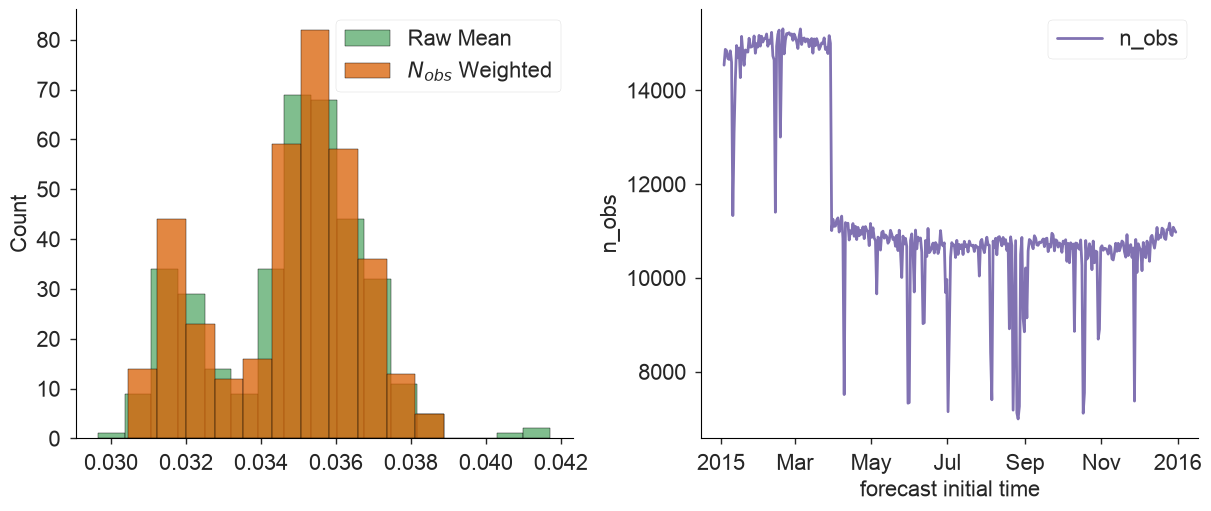

In [16]:
histplot("mae")

In [17]:
gds = xr.open_dataset("runs/v3/metrics/sla.per_group.nc")
gds = gds.squeeze()
gds.load()

<xarray.Dataset> Size: 52kB
Dimensions:     (t0: 362, group: 4)
Coordinates:
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (t0, group) float64 12kB 0.05313 0.05508 0.05131 ... 0.06092 nan
    mae         (t0, group) float64 12kB 0.03148 0.03358 0.03227 ... 0.03655 nan
    bias        (t0, group) float64 12kB 0.0001719 0.0003846 ... -0.001312 nan
    n_obs       (group, t0) int64 12kB 3472 3701 3617 3648 3411 ... 0 0 0 0 0

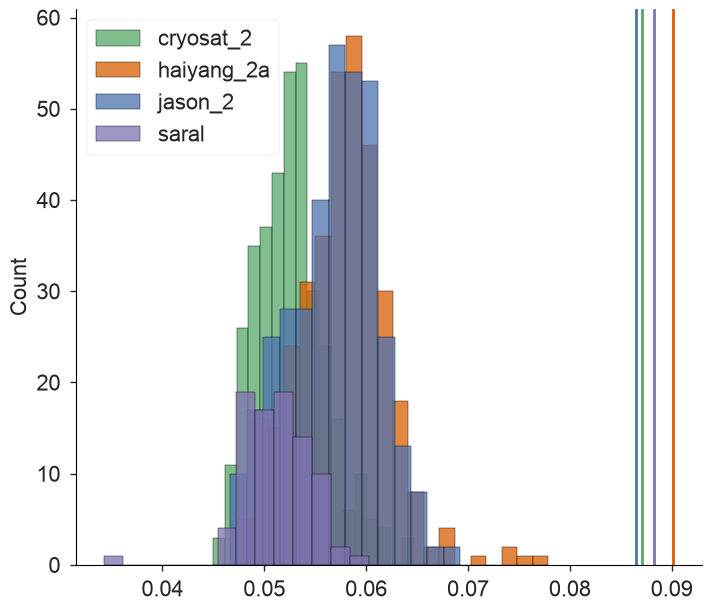

In [18]:
metric = "rmse"

fig, ax = plt.subplots()
for i, group in enumerate(gds.group.values):
    sns.histplot(
        gds[metric].sel(group=group),
        label=group,
        #alpha=.5
        color=f"C{i}",
    )
    ax.axvline(sds["stdev"].sel(variable=f"sla_filtered_{group}"), color=f"C{i}")
ax.legend();

## Observed at input

In [19]:
ods = xr.open_dataset("runs/v3/metrics/sla.by_region.all_groups.nc")
ods = ods.squeeze()
ods.load()

<xarray.Dataset> Size: 75kB
Dimensions:        (t0: 362, region: 3)
Coordinates:
  * t0             (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30...
    valid_time     (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31...
  * region         (region) <U12 144B 'seen_at_t0' 'seen_earlier' 'unseen'
    lead_time      timedelta64[ns] 8B 1 days
    fhr            int64 8B 24
Data variables:
    rmse           (t0, region) float64 9kB 0.04453 0.04925 ... 0.05657 0.07226
    mae            (t0, region) float64 9kB 0.02858 0.03052 ... 0.03345 0.04448
    bias           (t0, region) float64 9kB 0.0006911 -0.0007031 ... -0.002212
    n_live_groups  (t0, region) int64 9kB 4 4 4 4 4 4 4 4 4 ... 3 3 3 3 3 3 3 3
    rmse_pooled    (t0, region) float64 9kB 0.04439 0.04957 ... 0.05732 0.07266
    mae_pooled     (t0, region) float64 9kB 0.02854 0.03061 ... 0.03372 0.04511
    bias_pooled    (t0, region) float64 9kB 0.0005805 -0.0006955 ... -0.00255
    n_obs          (t0, region) int64 9kB 5005 6006 3526 5360 ... 3123 4258 3595

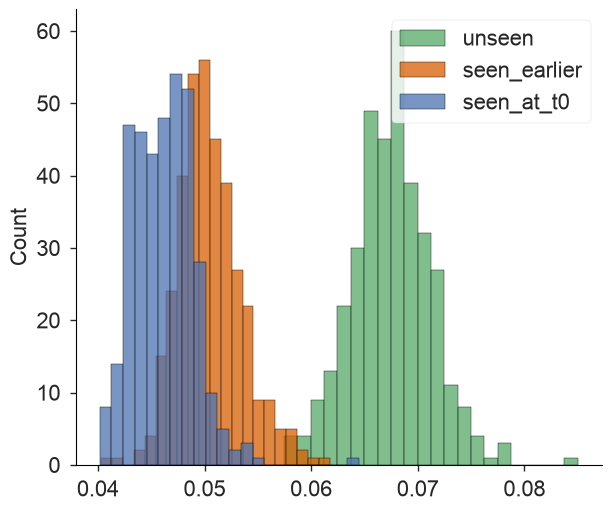

In [20]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(6,5))
for region in ["unseen", "seen_earlier", "seen_at_t0"]:
    sns.histplot(
        ods[metric].sel(region=region),
        label=region,
        #alpha=.5
    )
ax.legend();

In [75]:
ogds = [
    xr.open_dataset(f"runs/v{version}/metrics/sla.by_region.per_group.nc").squeeze().load().expand_dims({"version": [version]})
    for version in [0, 1, 2, 3, "3mft", 4]
]
ogds = xr.concat(ogds, dim="version")
ogds = ogds.drop_vars(["lead_time", "valid_time", "fhr"])
pds = (
    xr.open_dataset("runs/persistence-metrics/sla.pooled.per_group.nc").squeeze().load().expand_dims(
        {"version": ["pooled persistence"], "region": ["seen_at_t0"]})
).drop_vars(["lead_time", "fhr"])
ogds = xr.concat([ogds, pds], dim="version", join="outer")

In [76]:
def make_it_nice(ax):
    ax.set(
        xlabel="",
        ylabel=ax.get_ylabel().upper(),
        xticklabels=[x.get_text().replace("_"," ").capitalize() for x in ax.get_xticklabels()],
    )

In [77]:
def plot_observed_region(xds, metric, x="group", hue="region"):
    
    fig, ax = plt.subplots(figsize=(9,5))
    df = xds[metric].to_dataset().to_dataframe().reset_index()
    sns.violinplot(
        df,
        y=metric,
        x=x,
        #alpha=.5
        hue=hue,
    )

    groups = xds["group"].values
    if x == "group":
        stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
        x = np.arange(len(groups))
        
        ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
                  label="Training Std. Dev.")
    else:
        stdev = sds["stdev"].sel(variable="pooled").values
        ax.axhline(stdev, color="gray", lw=1.5, zorder=3, label="Training Std. Dev.")
        
        
    l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");
    
    make_it_nice(ax)
    return fig, ax

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


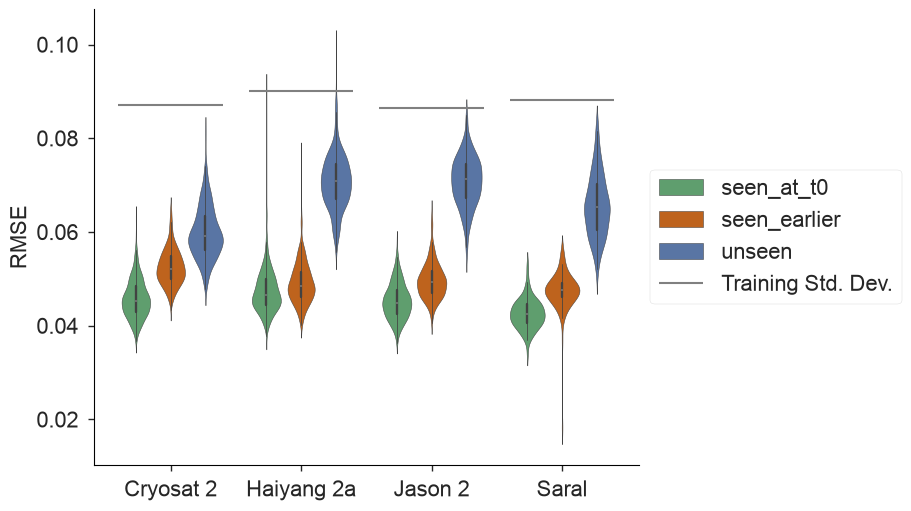

In [78]:
fig, ax = plot_observed_region(ogds.sel(version=3), "rmse");
#fig.savefig("runs/v3/figures/rmse_by_region_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


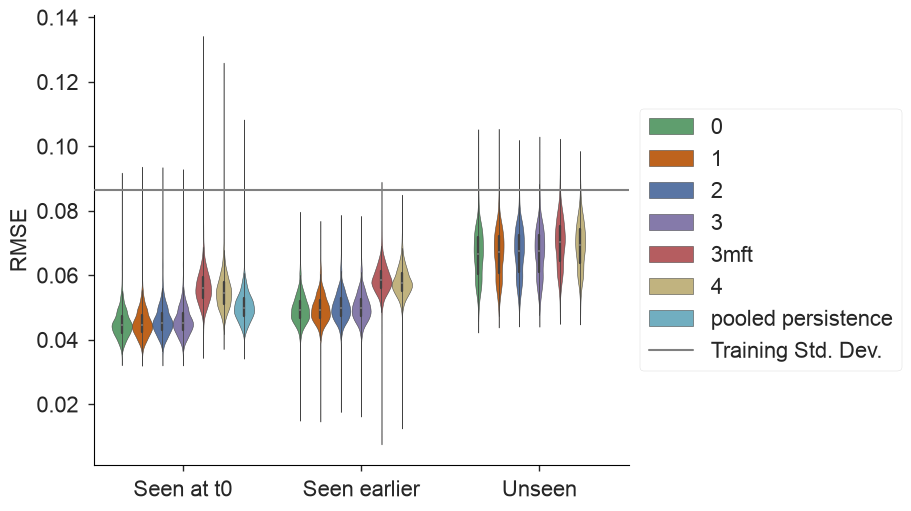

In [79]:
fig, ax = plot_observed_region(ogds, metric="rmse", x="region", hue="version")
fig.savefig(f"figures/rmse_vs_region_by_version.jpeg", dpi=300, bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


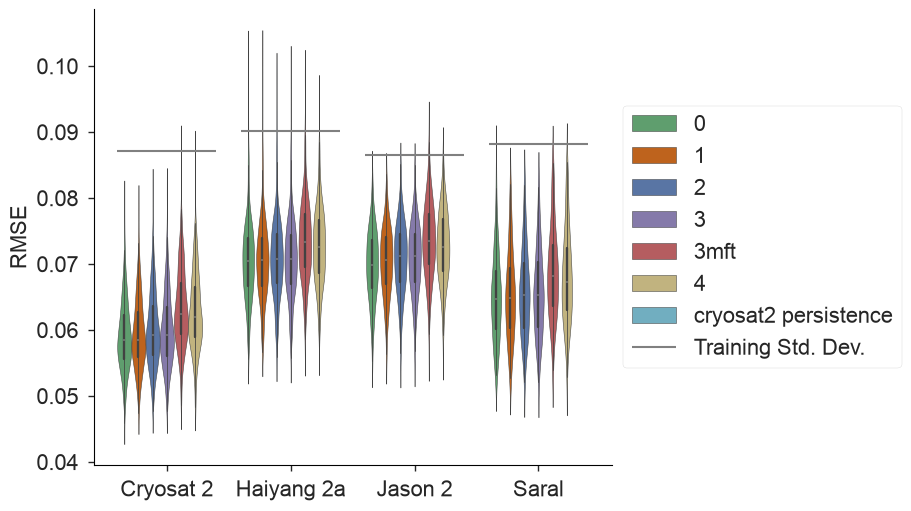

In [50]:
fig, ax = plot_observed_region(ogds.sel(region="unseen"), metric="rmse", hue="version")
#fig.savefig("figures/unseen_rmse_by_version_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


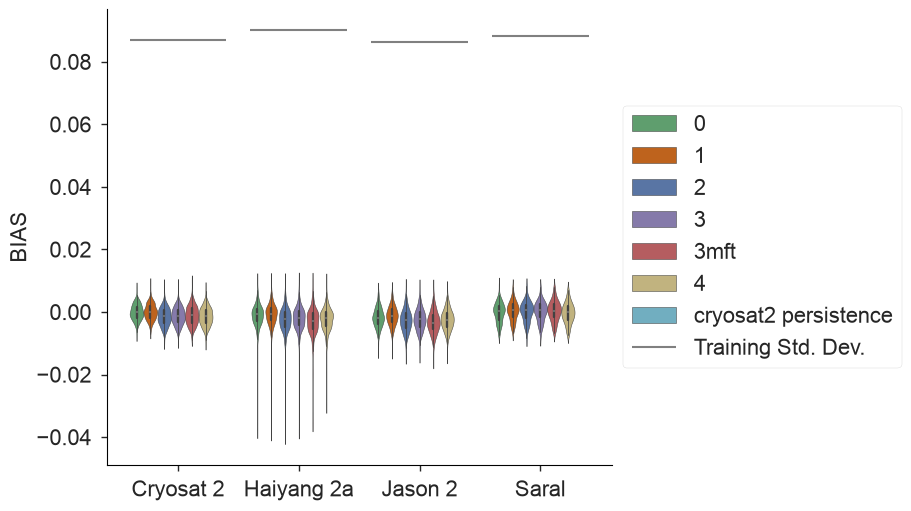

In [51]:
fig, ax = plot_observed_region(ogds.sel(region="unseen"), metric="bias", hue="version")
#fig.savefig("figures/unseen_bias_by_version_by_group.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


(<Figure size 900x500 with 1 Axes>, <Axes: ylabel='RMSE'>)

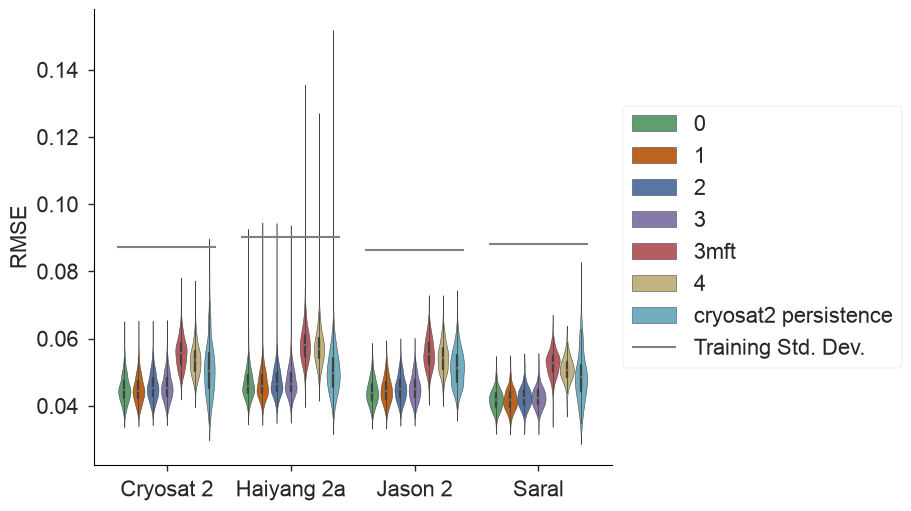

In [52]:
plot_observed_region(ogds.sel(region="seen_at_t0"), metric="rmse", hue="version")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_81494/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


(<Figure size 900x500 with 1 Axes>, <Axes: ylabel='RMSE'>)

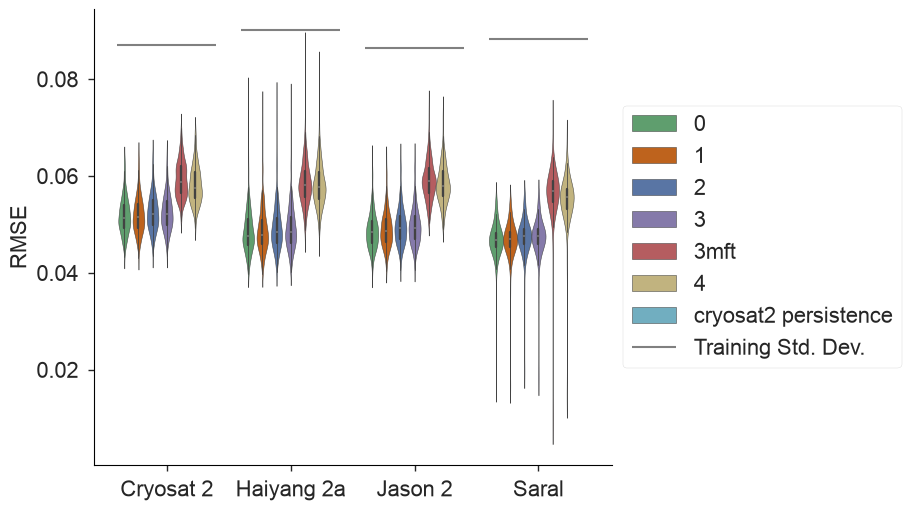

In [53]:
plot_observed_region(ogds.sel(region="seen_earlier"), metric="rmse", hue="version")

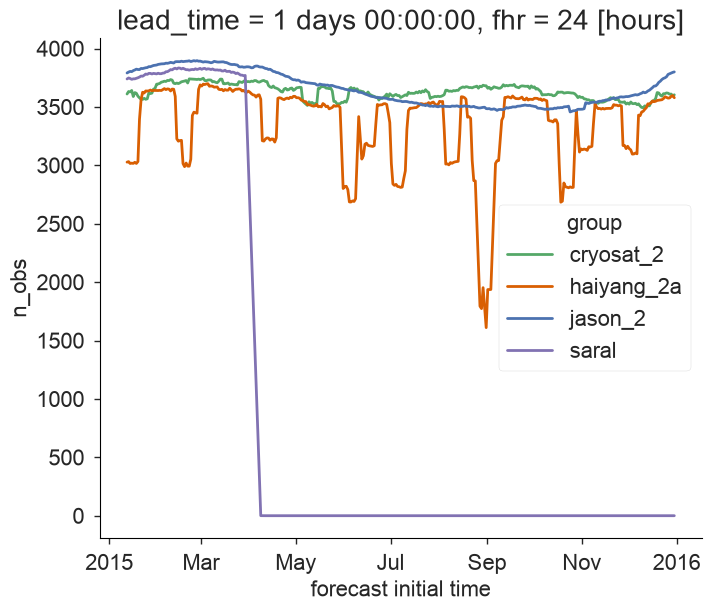

In [32]:
#gds.n_obs.plot.line(x="t0", alpha=.4)#, linestyle="", marker=".")
gds.n_obs.rolling({"t0": 10}).mean().plot.line(x="t0")

## Look at overlap degree

In [41]:
lgds = [
    xr.open_dataset(f"runs/v{version}/metrics/sla.by_overlap.per_group.nc").squeeze().load().expand_dims({"version": [version]})
    for version in [0, 1, 2, 3, "3mft", 4]
]
lgds = xr.concat(lgds, dim="version")
lgds.load()

<xarray.Dataset> Size: 1MB
Dimensions:     (version: 6, t0: 362, group: 4, n_overlap: 4)
Coordinates:
  * version     (version) object 48B 0 1 2 3 '3mft' 4
  * t0          (t0) datetime64[ns] 3kB 2015-01-03T12:00:00 ... 2015-12-30T12...
    valid_time  (t0) datetime64[ns] 3kB 2015-01-04T12:00:00 ... 2015-12-31T12...
  * group       (group) <U10 160B 'cryosat_2' 'haiyang_2a' 'jason_2' 'saral'
  * n_overlap   (n_overlap) int64 32B 1 2 3 4
    lead_time   timedelta64[ns] 8B 1 days
    fhr         int64 8B 24
Data variables:
    rmse        (version, t0, group, n_overlap) float64 278kB 0.04732 ... nan
    mae         (version, t0, group, n_overlap) float64 278kB 0.02961 ... nan
    bias        (version, t0, group, n_overlap) float64 278kB 0.001013 ... nan
    n_obs       (version, group, t0, n_overlap) int64 278kB 2417 906 139 ... 0 0

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_80733/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


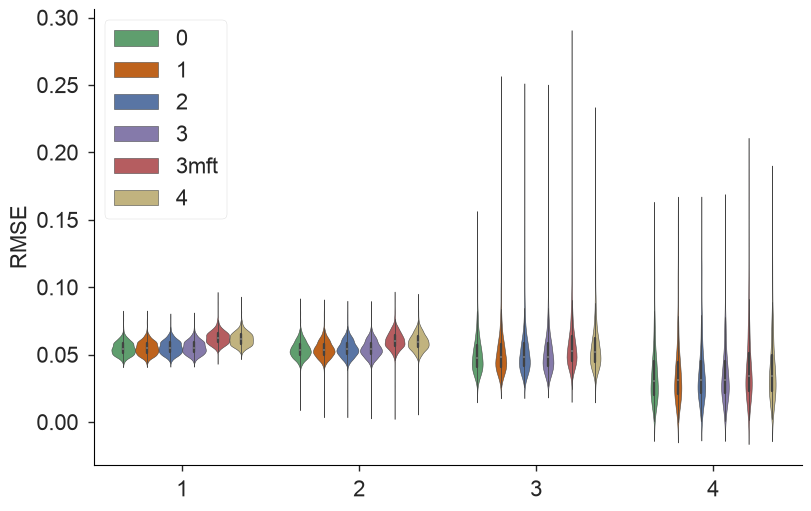

In [43]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(8,5))
df = lgds[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    x="n_overlap",
    y="rmse",
    hue="version",
)
ax.legend();
make_it_nice(ax)
#fig.savefig(f"runs/v3/figures/rmse_by_overlap.jpeg", bbox_inches="tight")

/var/folders/0k/gh0lwxg17l1_fbtvplvt45s40000gp/T/ipykernel_80733/1547974153.py:2: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(


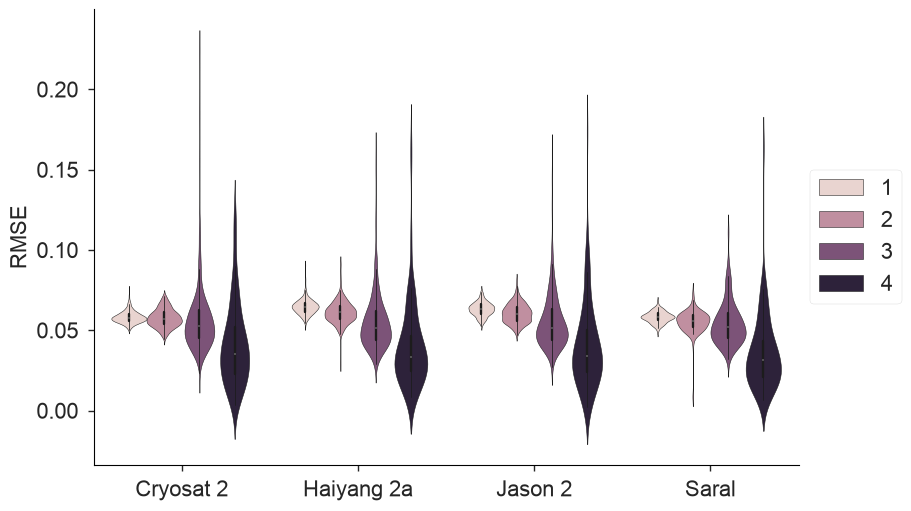

In [44]:
metric = "rmse"

fig, ax = plt.subplots(figsize=(9,5))
df = lgds.sel(version=4)[metric].to_dataset().to_dataframe().reset_index()
sns.violinplot(
    df,
    y="rmse",
    x="group",
    #alpha=.5
    hue="n_overlap",
)

#groups = lgds["group"].values
#stdev = sds["stdev"].sel(variable=[f"sla_filtered_{g}" for g in groups]).values
#print(groups)
#x = np.arange(len(groups))
#
#ax.hlines(stdev, x - 0.4, x + 0.4, color="gray", lw=1.5, zorder=3,
#          label="Training Std. Dev.")
    
l = ax.legend(bbox_to_anchor=(1., .5), loc="center left");

make_it_nice(ax)
#fig.savefig(f"runs/v3/figures/rmse_by_overlap_by_group.jpeg", bbox_inches="tight")